# Práctica: Grover

![](images/grover.png)

## Consignas

### Ejercicio 1

Implemente el algoritmo de Grover con el siguiente oráculo (Detector):

i. CCZ de 3 qubits

ii. CCCCZ de 5 qubits

### Ejercicio 2

Implemente 1.i) y 1.ii) para diferente cantidad de iteraciones Oráculo-Grover.

### Ejercicio 3

Implemente el algoritmo Grover para la función booleana x2’x1.x0. Determine el número ideal de iteraciones Oráculo-Grover. Justifique su respuesta.

### Ejercicio 4

Implemente el algoritmo Grover para la función booleana vista en la teoría, x2’x1’x0 + x2.x1.x0’. Determine el número ideal de iteraciones Oráculo-Grover. Justifique respuesta

# Importaciones

A continuación, se realiza la importación de las bibliotecas necesarias para resolver esta práctica.

In [ ]:
from math import pi
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import HGate, XGate
from qiskit.circuit import Gate
from itertools import product
from qiskit.quantum_info import Operator
import pandas as pd
import numpy as np

from collections import Counter, defaultdict

import matplotlib
import matplotlib.pyplot as plt

## Resoluciones

### Ejercicio 1

Se realiza la implementación del operador de Grover. Para ello, primero se define la siguiente función auxiliar, la cual permite aplicar una compuerta a todos los qubits de un circuito arbitrario.

In [ ]:
def apply_gate_to_every_qubit(qubits: int, qc: QuantumCircuit, gate):
    for i in range(qubits):
        qc.append(gate, [i])

In [ ]:
def grover_operator(qubits: int):

    qc = QuantumCircuit(qubits, name="G")

    # Se colocan las hadamards iniciales.
    apply_gate_to_every_qubit(qubits, qc, HGate())

    # Se colocan nots en todos los qubits.
    apply_gate_to_every_qubit(qubits, qc, XGate())

    # Se enlazan los n-1 qubits al n-ésimo qubit
    # a través de un controlled.
    qc.mcp(np.pi, list(range(qubits - 1)), qubits - 1)
    
    # Otra forma de escribir el código anterior es la siguiente.
    # controlled_gate = ZGate().control(qubits - 1)
    # qc.append(controlled_gate, list(range(qubits)))
    # No obstante, lo malo de esta forma es que la compuerta Z no puede
    # visualizar correctamente. Esto se debe a que Qiskit dibuja las compuertas
    # Z multicontroladas de forma simétrica: todos los qubits aparecen con un punto
    # y ninguno con una caja “Z”. Con Z controlada no hay un control y un objetivo
    # distinguibles, porque la compuerta es simétrica en todos sus qubits, así que
    # Qiskit no marca a ninguno como objetivo. Es el mismo motivo por el que el CZ
    # se ve con dos puntos.

    # Se colocan nots en todos los qubits.
    apply_gate_to_every_qubit(qubits, qc, XGate())

    # Se colocan los hadamards finales.
    apply_gate_to_every_qubit(qubits, qc, HGate())

    return qc

Se comprueba visualmente que el circuito se diseñó correctamente:

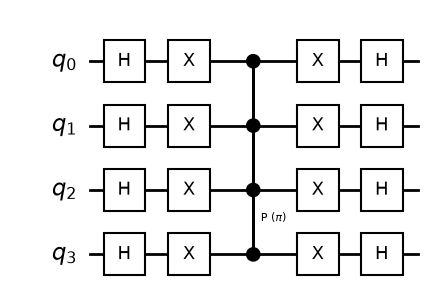

In [28]:
grover_operator(4).draw(output='mpl', style='bw')

Se realiza adicionalmente la comprobación utilizando la matriz:

In [ ]:
n = 3
G = Operator(grover_operator(n))
s = np.ones(2**n) / np.sqrt(2**n)

# Debería dar I - 2|s><s|.
print(np.allclose(G.data, np.eye(2**n) - 2 * np.outer(s, s)))

True


Como puede observarse, el operador está correctamente implementado y la equivalencia se cumple.

Se implementa ahora el algoritmo que, dado un oráculo, devuelva el circuito con el algoritmo de Grover correspondiente:

In [ ]:
def grover(qubits: int, oraculo: QuantumCircuit, iteraciones: int = 1):

    qc = QuantumCircuit(qubits, name="Grover")

    # Se aplica Hadamard a todos los qubits.
    apply_gate_to_every_qubit(qubits, qc, HGate())
    
    # Se applica el oráculo a todos los qubits.
    qc.append(oraculo)

Con lo anterior realizado, se realiza la implementación de los oráculos solicitados en cada uno de los inciso.

#### Inciso I)

El oráculo es: CCZ de 3 qubits.

Se realiza la implementación de una función que permita obtener el oráculo mencionado, con extensibilidad a $n$ qubits, para poder reutilizarla en el ejercicio 2.

In [33]:
def get_oraculo(qubits: int):

    qc = QuantumCircuit(qubits, name="U")

    # Se enlazan los n-1 qubits al n-ésimo qubit
    # a través de un controlled.
    qc.mcp(np.pi, list(range(qubits - 1)), qubits - 1)
    
    return qc

Se obtiene el oráculo de 3 qubits y se visualiza.

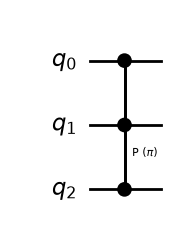

In [ ]:
oraculo = get_oraculo(3)
oraculo.draw(output='mpl', style='bw')

Se construye el algoritmo de Grover con dicho oráculo, con 1 iteración: